# Comparing Pre-trained `torchvision` Models on a Tom & Jerry Image Classification Dataset

**Task:** classify each cartoon frame into one of four classes based on which characters appear:

| Class | Meaning | Folder |
|---|---|---|
| `neither` | Neither Tom nor Jerry visible | `tom_jerry_0` |
| `tom` | Only Tom visible | `tom` |
| `jerry` | Only Jerry visible | `jerry` |
| `both` | Tom and Jerry both visible | `tom_jerry_1` |

**Approach:** ImageNet has no Tom/Jerry classes, so the pre-trained models cannot be used for inference as-is.
Each model is used as a **frozen feature extractor** (its ImageNet weights are untouched), and a small linear classification head
is trained on the extracted features. This isolates the quality of each architecture's learned representation and keeps the
whole comparison cheap enough to run on a free Colab GPU or even a CPU.

Models compared (5): ResNet-50, DenseNet-121, MobileNetV3-Large, EfficientNet-B0, ViT-B/16.

## 1. Setup

In [2]:
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128

Looking in indexes: https://download.pytorch.org/whl/cu128
  Using cached torch-2.11.0%2Bcu128-cp314-cp314-win_amd64.whl.metadata (29 kB)
  Using cached torchvision-0.26.0%2Bcu128-cp314-cp314-win_amd64.whl.metadata (5.6 kB)
  Using cached setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/2.8 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:55
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:55
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:55
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:54
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:54
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:54
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:54
   ---------------------------------------- 0.0/2.8 GB 11.8 MB/s eta 0:03:53
   --------------------

In [1]:
#!pip install scikit-learn pandas matplotlib seaborn

In [1]:
# !pip install torch torchvision scikit-learn pandas matplotlib seaborn   # uncomment if needed
import os, time, random, zipfile, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda


## 2. Locate and organize the dataset

Set `ZIP_PATH` to your zip file (on Colab, upload it or mount Drive). The cell extracts it once and finds the class folders automatically.

In [2]:
ZIP_PATH = "tom & jerry image classification.zip"   # <- change if your file lives elsewhere
EXTRACT_DIR = "tom_jerry_data"

if not os.path.isdir(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

# find the directory that contains the four class folders
DATA_ROOT = None
for root, dirs, _ in os.walk(EXTRACT_DIR):
    if {"tom", "jerry", "tom_jerry_0", "tom_jerry_1"} <= set(dirs):
        DATA_ROOT = root; break
assert DATA_ROOT, "Could not find class folders"
print("Data root:", DATA_ROOT)

# folder name -> readable class name
FOLDER_TO_CLASS = {"tom_jerry_0": "neither", "tom": "tom", "jerry": "jerry", "tom_jerry_1": "both"}
CLASS_NAMES = ["neither", "tom", "jerry", "both"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}

rows = []
for folder, cname in FOLDER_TO_CLASS.items():
    for p in glob.glob(os.path.join(DATA_ROOT, folder, "*.jpg")):
        rows.append({"path": p, "label_name": cname, "label": CLASS_TO_IDX[cname]})
df = pd.DataFrame(rows)
print(f"Total images: {len(df)}")
df["label_name"].value_counts()

Data root: tom_jerry_data\tom_and_jerry\tom_and_jerry
Total images: 5478


label_name
tom        1930
neither    1528
jerry      1240
both        780
Name: count, dtype: int64

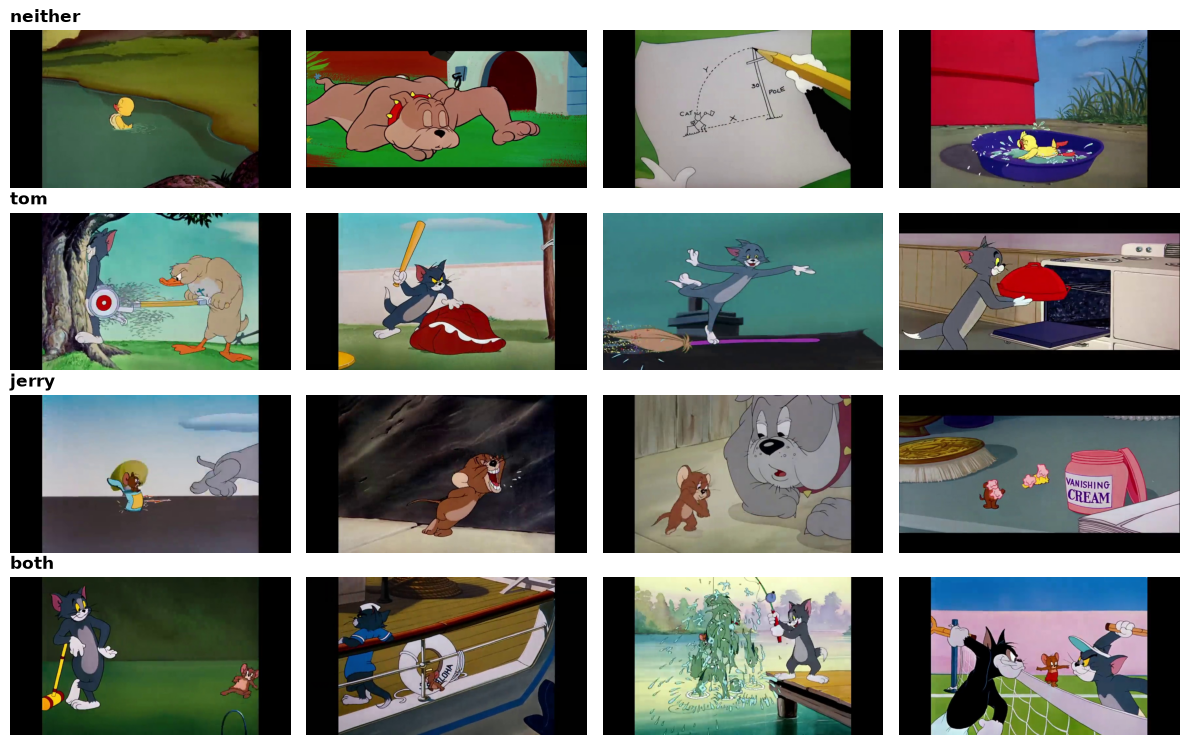

In [3]:
# Visual sanity check: 4 random examples per class
fig, axes = plt.subplots(4, 4, figsize=(12, 7.5))
for r, c in enumerate(CLASS_NAMES):
    sample = df[df.label_name == c].sample(4, random_state=SEED)
    for k, (_, row) in enumerate(sample.iterrows()):
        axes[r, k].imshow(Image.open(row.path)); axes[r, k].axis("off")
        if k == 0: axes[r, k].set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

### Stratified train / validation / test split (70 / 15 / 15)

The train split fits the linear head, the validation split chooses the best training epoch, and the **test split is used only for the final comparison**.

In [4]:
train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df  = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label, random_state=SEED)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):5d} ", d.label_name.value_counts().reindex(CLASS_NAMES).to_dict())

train n= 3834  {'neither': 1069, 'tom': 1351, 'jerry': 868, 'both': 546}
val   n=  822  {'neither': 230, 'tom': 289, 'jerry': 186, 'both': 117}
test  n=  822  {'neither': 229, 'tom': 290, 'jerry': 186, 'both': 117}


## 3. Custom PyTorch `Dataset` and `DataLoader`s

`TomJerryDataset` reads a dataframe of image paths and labels, loads each image as RGB, and applies a transform.
Each torchvision model ships with its own preprocessing recipe (`weights.transforms()`) specifying resize size, crop size, interpolation, and normalization, so a separate dataset/loader set is built per model.

In [7]:
class TomJerryDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.paths = dataframe["path"].tolist()
        self.labels = dataframe["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[idx]

def make_loaders(transform, batch_size=64, num_workers=0):
    mk = lambda d: DataLoader(TomJerryDataset(d, transform), batch_size=batch_size,
                              shuffle=False, num_workers=num_workers,
                              pin_memory=(DEVICE.type == "cuda"))
    return mk(train_df), mk(val_df), mk(test_df)

## 4. Models from `torchvision.models`

Each entry gives the constructor, the weights enum, and how to strip the ImageNet classification layer so the network outputs a feature vector.

In [8]:
def strip_resnet(m):      m.fc = nn.Identity();          return m
def strip_densenet(m):    m.classifier = nn.Identity();  return m
def strip_classifier(m):  m.classifier = nn.Identity();  return m   # MobileNetV3 / EfficientNet
def strip_vit(m):         m.heads = nn.Identity();       return m

MODEL_ZOO = {
    "ResNet-50":         (models.resnet50,         models.ResNet50_Weights.IMAGENET1K_V2,         strip_resnet),
    "DenseNet-121":      (models.densenet121,      models.DenseNet121_Weights.IMAGENET1K_V1,      strip_densenet),
    "MobileNetV3-Large": (models.mobilenet_v3_large, models.MobileNet_V3_Large_Weights.IMAGENET1K_V2, strip_classifier),
    "EfficientNet-B0":   (models.efficientnet_b0,  models.EfficientNet_B0_Weights.IMAGENET1K_V1,  strip_classifier),
    "ViT-B/16":          (models.vit_b_16,         models.ViT_B_16_Weights.IMAGENET1K_V1,         strip_vit),
}

# Input requirements and size of each model
for name, (ctor, w, _) in MODEL_ZOO.items():
    t = w.transforms()
    n_params = sum(p.numel() for p in ctor(weights=None).parameters()) / 1e6
    print(f"{name:18s} params={n_params:6.1f}M  resize={t.resize_size}  crop={t.crop_size}  interp={t.interpolation.value}")

ResNet-50          params=  25.6M  resize=[232]  crop=[224]  interp=bilinear
DenseNet-121       params=   8.0M  resize=[256]  crop=[224]  interp=bilinear
MobileNetV3-Large  params=   5.5M  resize=[232]  crop=[224]  interp=bilinear
EfficientNet-B0    params=   5.3M  resize=[256]  crop=[224]  interp=bicubic
ViT-B/16           params=  86.6M  resize=[256]  crop=[224]  interp=bilinear


## 5. Feature extraction (inference through the frozen backbones)

All backbone weights are frozen and run in `eval()` mode under `torch.no_grad()`. Features are cached to disk so re-runs are fast. The time per image is recorded as an inference-cost measure.

In [9]:
@torch.no_grad()
def extract_features(backbone, loader):
    backbone.eval()
    feats, labels = [], []
    for x, y in loader:
        feats.append(backbone(x.to(DEVICE)).float().cpu())
        labels.append(y)
    return torch.cat(feats), torch.cat(labels)

FEATURES, INFER_MS, PARAMS_M = {}, {}, {}
os.makedirs("feature_cache", exist_ok=True)

for name, (ctor, weights, strip) in MODEL_ZOO.items():
    cache = f"feature_cache/{name.replace('/', '_')}.pt"
    PARAMS_M[name] = sum(p.numel() for p in ctor(weights=None).parameters()) / 1e6
    if os.path.exists(cache):
        FEATURES[name], INFER_MS[name] = torch.load(cache)["f"], torch.load(cache)["ms"]
        print(f"[cached] {name}"); continue

    print(f"Extracting: {name} ...")
    backbone = strip(ctor(weights=weights)).to(DEVICE)
    for p in backbone.parameters(): p.requires_grad = False
    tr, va, te = make_loaders(weights.transforms())

    f = {}
    t0 = time.time()
    f["train"] = extract_features(backbone, tr)
    f["val"]   = extract_features(backbone, va)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    f["test"]  = extract_features(backbone, te)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    total_imgs = len(train_df) + len(val_df) + len(test_df)
    ms = (time.time() - t0) / total_imgs * 1000       # includes image loading + preprocessing
    FEATURES[name], INFER_MS[name] = f, ms
    torch.save({"f": f, "ms": ms}, cache)
    print(f"   feature dim = {f['train'][0].shape[1]}, {ms:.1f} ms/image")
    del backbone
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

Extracting: ResNet-50 ...
   feature dim = 2048, 18.0 ms/image
Extracting: DenseNet-121 ...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\emangwapo/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:02<00:00, 11.6MB/s]


   feature dim = 1024, 10.9 ms/image
Extracting: MobileNetV3-Large ...
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\emangwapo/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:01<00:00, 11.6MB/s]


   feature dim = 960, 9.8 ms/image
Extracting: EfficientNet-B0 ...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\emangwapo/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:01<00:00, 11.5MB/s]


   feature dim = 1280, 13.0 ms/image
Extracting: ViT-B/16 ...
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\emangwapo/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:29<00:00, 11.6MB/s] 


   feature dim = 768, 15.1 ms/image


## 6. Train a linear classification head on each set of features

A single `nn.Linear` layer on standardized features, trained with Adam and cross-entropy loss.
The epoch with the best **validation** accuracy is kept. Because the data is mildly imbalanced, class weights are used.

In [10]:
def train_head(feats, epochs=200, lr=1e-3, wd=1e-4):
    Xtr, ytr = feats["train"]; Xva, yva = feats["val"]
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    Xtr, Xva = (Xtr - mu) / sd, (Xva - mu) / sd
    Xtr, ytr, Xva, yva = Xtr.to(DEVICE), ytr.to(DEVICE), Xva.to(DEVICE), yva.to(DEVICE)

    counts = torch.bincount(ytr, minlength=len(CLASS_NAMES)).float()
    cw = (counts.sum() / (len(CLASS_NAMES) * counts)).to(DEVICE)

    head = nn.Linear(Xtr.shape[1], len(CLASS_NAMES)).to(DEVICE)
    opt = torch.optim.Adam(head.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.CrossEntropyLoss(weight=cw)

    best_acc, best_state = -1, None
    for ep in range(epochs):
        head.train()
        perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(Xtr), 128):
            idx = perm[i:i+128]
            opt.zero_grad(); lossf(head(Xtr[idx]), ytr[idx]).backward(); opt.step()
        head.eval()
        with torch.no_grad():
            acc = (head(Xva).argmax(1) == yva).float().mean().item()
        if acc > best_acc:
            best_acc, best_state = acc, {k: v.clone() for k, v in head.state_dict().items()}
    head.load_state_dict(best_state)
    return head, mu, sd, best_acc

HEADS = {}
for name in MODEL_ZOO:
    HEADS[name] = train_head(FEATURES[name])
    print(f"{name:18s} best val acc = {HEADS[name][3]:.4f}")

ResNet-50          best val acc = 0.8796
DenseNet-121       best val acc = 0.8735
MobileNetV3-Large  best val acc = 0.8564
EfficientNet-B0    best val acc = 0.8625
ViT-B/16           best val acc = 0.8893


## 7. Evaluation on the held-out test set

In [11]:
@torch.no_grad()
def predict(name):
    head, mu, sd, _ = HEADS[name]
    X, y = FEATURES[name]["test"]
    logits = head(((X - mu) / sd).to(DEVICE))
    return y.numpy(), logits.argmax(1).cpu().numpy()

results, PREDS = [], {}
for name in MODEL_ZOO:
    y_true, y_pred = predict(name)
    PREDS[name] = (y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    results.append({
        "Model": name,
        "Params (M)": round(PARAMS_M[name], 1),
        "Feature dim": FEATURES[name]["test"][0].shape[1],
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1,
        "ms / image": round(INFER_MS[name], 1),
    })

res_df = pd.DataFrame(results).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
res_df.style.format({c: "{:.4f}" for c in ["Accuracy","Precision (macro)","Recall (macro)","F1 (macro)"]}) \
            .background_gradient(subset=["Accuracy","F1 (macro)"], cmap="Greens")

,Model,Params (M),Feature dim,Accuracy,Precision (macro),Recall (macro),F1 (macro),ms / image
0,ViT-B/16,86.600000,768,0.8491,0.8361,0.8538,0.8430,15.100000
1,DenseNet-121,8.000000,1024,0.8358,0.8243,0.8400,0.8307,10.900000
2,ResNet-50,25.600000,2048,0.8285,0.8197,0.8302,0.8245,18.000000
3,EfficientNet-B0,5.300000,1280,0.8333,0.8185,0.8235,0.8209,13.000000
4,MobileNetV3-Large,5.500000,960,0.8273,0.8199,0.8213,0.8205,9.800000


In [12]:
# Per-class report for each model
for name in res_df.Model:
    print("="*70, f"\n{name}\n", "="*70)
    print(classification_report(*PREDS[name], target_names=CLASS_NAMES, digits=4, zero_division=0))

ViT-B/16
              precision    recall  f1-score   support

     neither     0.8298    0.8515    0.8405       229
         tom     0.9278    0.8414    0.8825       290
       jerry     0.8333    0.8333    0.8333       186
        both     0.7536    0.8889    0.8157       117

    accuracy                         0.8491       822
   macro avg     0.8361    0.8538    0.8430       822
weighted avg     0.8543    0.8491    0.8502       822

DenseNet-121
              precision    recall  f1-score   support

     neither     0.8165    0.7773    0.7964       229
         tom     0.8959    0.8310    0.8623       290
       jerry     0.8252    0.9140    0.8673       186
        both     0.7597    0.8376    0.7967       117

    accuracy                         0.8358       822
   macro avg     0.8243    0.8400    0.8307       822
weighted avg     0.8384    0.8358    0.8357       822

ResNet-50
              precision    recall  f1-score   support

     neither     0.8000    0.8035    0.8017

In [13]:
# Character-level view: "Is Tom present?" and "Is Jerry present?" derived from the 4-class prediction
TOM_IDX   = {CLASS_TO_IDX["tom"],   CLASS_TO_IDX["both"]}
JERRY_IDX = {CLASS_TO_IDX["jerry"], CLASS_TO_IDX["both"]}
rows = []
for name in res_df.Model:
    yt, yp = PREDS[name]
    for char, idxs in [("Tom", TOM_IDX), ("Jerry", JERRY_IDX)]:
        a = np.isin(yt, list(idxs)); b = np.isin(yp, list(idxs))
        p, r, f, _ = precision_recall_fscore_support(a, b, average="binary", zero_division=0)
        rows.append({"Model": name, "Character": char, "Accuracy": accuracy_score(a, b),
                     "Precision": p, "Recall": r, "F1": f})
char_df = pd.DataFrame(rows)
char_df.pivot(index="Model", columns="Character", values=["Precision","Recall","F1"]).round(4).loc[res_df.Model]

Precision          Recall              F1        
Character             Jerry     Tom   Jerry     Tom   Jerry     Tom
Model                                                              
ViT-B/16             0.8488  0.9377  0.9076  0.9238  0.8772  0.9307
DenseNet-121         0.8269  0.9296  0.9142  0.9091  0.8683  0.9193
ResNet-50            0.8423  0.9129  0.8812  0.9017  0.8613  0.9073
EfficientNet-B0      0.8526  0.9104  0.8779  0.8993  0.8650  0.9048
MobileNetV3-Large    0.8502  0.9177  0.8614  0.9042  0.8557  0.9109

## 8. Visual comparison

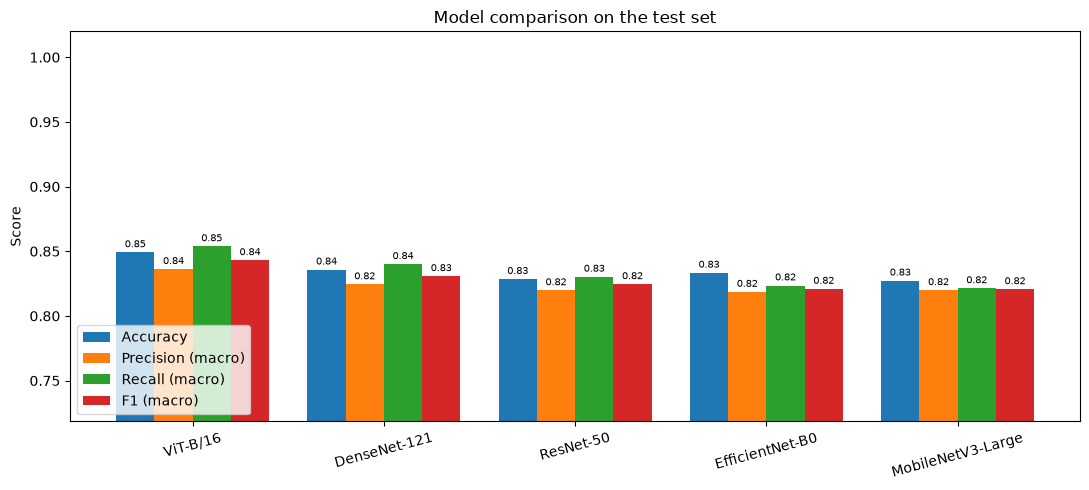

In [14]:
# (a) Grouped bar chart of the four metrics
metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
x = np.arange(len(res_df)); w = 0.2
fig, ax = plt.subplots(figsize=(11, 5))
for i, m in enumerate(metrics):
    bars = ax.bar(x + (i - 1.5) * w, res_df[m], w, label=m)
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax.set_xticks(x); ax.set_xticklabels(res_df.Model, rotation=15)
ax.set_ylim(max(0, res_df[metrics].min().min() - 0.1), 1.02)
ax.set_ylabel("Score"); ax.set_title("Model comparison on the test set"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

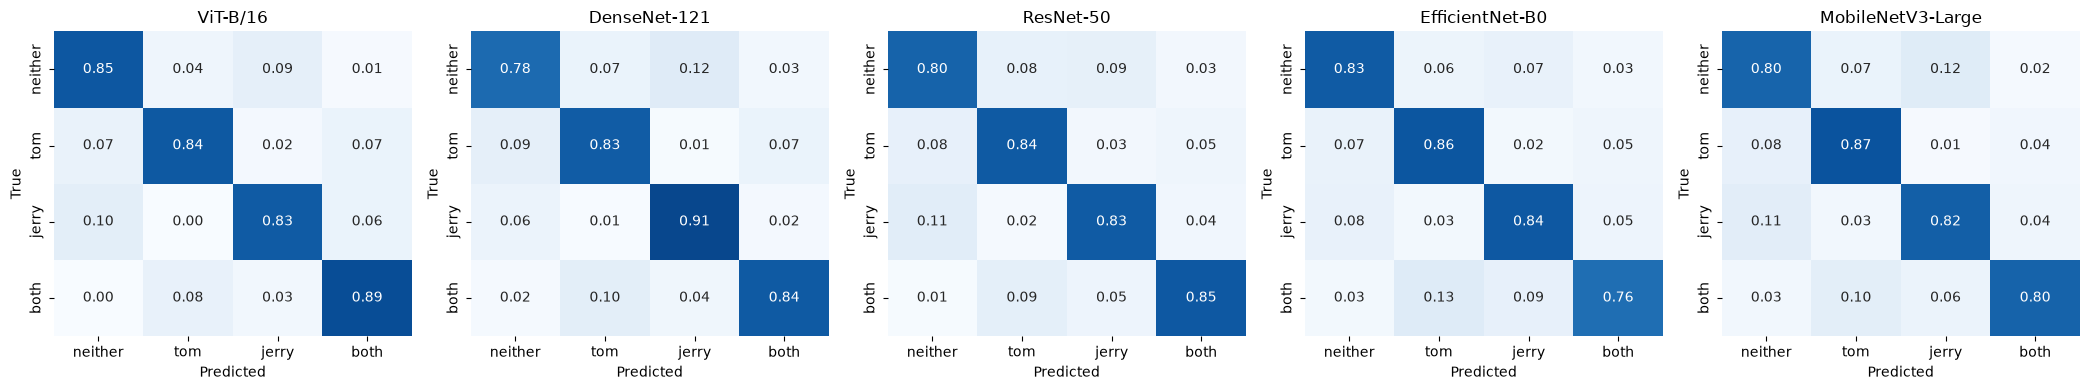

In [15]:
# (b) Confusion matrices (row-normalised)
fig, axes = plt.subplots(1, len(res_df), figsize=(4.2 * len(res_df), 4))
for ax, name in zip(axes, res_df.Model):
    cm = confusion_matrix(*PREDS[name], labels=range(len(CLASS_NAMES)), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

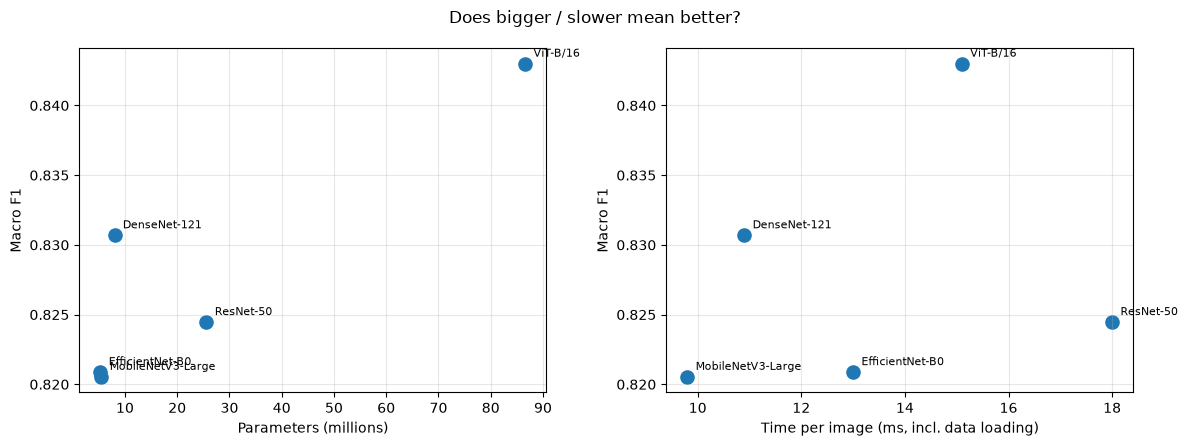

In [16]:
# (c) Accuracy vs. model size and vs. cost
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, lab in zip(axes, ["Params (M)", "ms / image"], ["Parameters (millions)", "Time per image (ms, incl. data loading)"]):
    ax.scatter(res_df[col], res_df["F1 (macro)"], s=90)
    for _, r in res_df.iterrows():
        ax.annotate(r.Model, (r[col], r["F1 (macro)"]), textcoords="offset points", xytext=(6, 5), fontsize=8)
    ax.set_xlabel(lab); ax.set_ylabel("Macro F1"); ax.grid(alpha=.3)
plt.suptitle("Does bigger / slower mean better?"); plt.tight_layout(); plt.show()

ViT-B/16: 124 errors out of 822 test images


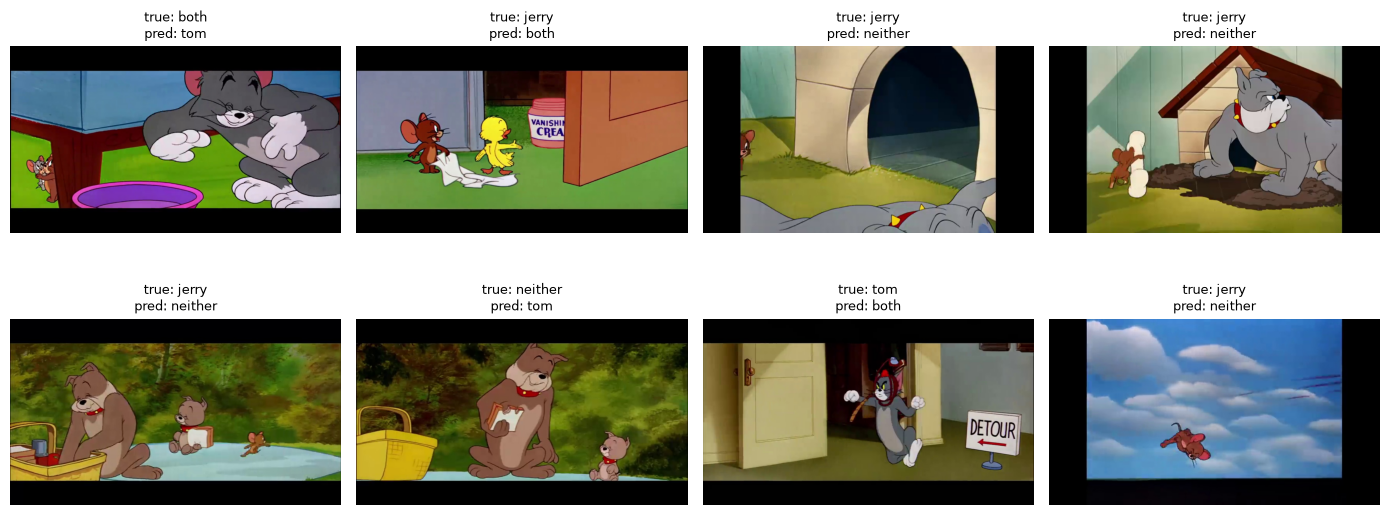

In [17]:
# (d) Most common mistakes of the best model
best = res_df.Model[0]
yt, yp = PREDS[best]
test_idx = test_df.reset_index(drop=True)
wrong = np.where(yt != yp)[0]
print(f"{best}: {len(wrong)} errors out of {len(yt)} test images")
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, i in zip(axes.ravel(), np.random.RandomState(SEED).permutation(wrong)[:8]):
    ax.imshow(Image.open(test_idx.path[i])); ax.axis("off")
    ax.set_title(f"true: {CLASS_NAMES[yt[i]]}\npred: {CLASS_NAMES[yp[i]]}", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Analysis and conclusion

Run the cell below to print the headline findings from your actual results, then read the discussion that follows.

In [18]:
b, w_ = res_df.iloc[0], res_df.iloc[-1]
print(f"Best model : {b.Model}  (acc={b.Accuracy:.3f}, macro-F1={b['F1 (macro)']:.3f}, {b['Params (M)']} M params)")
print(f"Worst model: {w_.Model}  (acc={w_.Accuracy:.3f}, macro-F1={w_['F1 (macro)']:.3f}, {w_['Params (M)']} M params)")
print(f"Spread between best and worst macro-F1: {b['F1 (macro)'] - w_['F1 (macro)']:.3f}")
fastest = res_df.sort_values('ms / image').iloc[0]
print(f"Fastest    : {fastest.Model} ({fastest['ms / image']} ms/image, macro-F1={fastest['F1 (macro)']:.3f})")
pc = pd.DataFrame({n: pd.Series(precision_recall_fscore_support(*PREDS[n], average=None, zero_division=0)[2], index=CLASS_NAMES) for n in res_df.Model})
print("\nMean per-class F1 across models (hardest class = lowest):"); print(pc.mean(axis=1).sort_values().round(3))

Best model : ViT-B/16  (acc=0.849, macro-F1=0.843, 86.6 M params)
Worst model: MobileNetV3-Large  (acc=0.827, macro-F1=0.821, 5.5 M params)
Spread between best and worst macro-F1: 0.022
Fastest    : MobileNetV3-Large (9.8 ms/image, macro-F1=0.821)

Mean per-class F1 across models (hardest class = lowest):
both       0.795
neither    0.814
jerry      0.833
tom        0.870
dtype: float64


## Results, Analysis and Conclusion

### Summary of results (test set, n = 822)

| Model | Params (M) | Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | ms / image |
|---|---|---|---|---|---|---|
| **ViT-B/16** | 86.6 | **0.8491** | **0.8361** | **0.8538** | **0.8430** | 15.1 |
| DenseNet-121 | 8.0 | 0.8358 | 0.8243 | 0.8400 | 0.8307 | 10.9 |
| ResNet-50 | 25.6 | 0.8285 | 0.8197 | 0.8302 | 0.8245 | 18.0 |
| EfficientNet-B0 | 5.3 | 0.8333 | 0.8185 | 0.8235 | 0.8209 | 13.0 |
| MobileNetV3-Large | 5.5 | 0.8273 | 0.8199 | 0.8213 | 0.8205 | 9.8 |

ViT-B/16 ranked first on every metric (macro-F1 = 0.843) and MobileNetV3-Large last (macro-F1 = 0.821), a spread of only **2.2 points** in macro-F1.
MobileNetV3-Large was the fastest model (9.8 ms/image).

### Key findings

**1. The models are closer than they look.** All five models land between 82.7% and 84.9% accuracy. With 822 test images, the 95% margin of error on a single accuracy figure is roughly ±2.6 points,
so the gap between the best and worst model is about the size of the noise. ViT-B/16 is the best in this run, but the ranking among the other four (DenseNet, EfficientNet, ResNet, MobileNet)
is not statistically reliable. A different random split could reorder them.

**2. Model size did not translate into proportional gains.** ViT-B/16 has 86.6M parameters, about 16x more than MobileNetV3-Large (5.5M), yet it gains only about 2 points of macro-F1.
DenseNet-121 (8.0M) beat the larger ResNet-50 (25.6M) on all four metrics, and the two smallest models (EfficientNet-B0 at 5.3M and MobileNetV3-Large at 5.5M)
finished within 0.01 F1 of ResNet-50. Past a certain point, extra capacity gave diminishing returns on this task.
In terms of accuracy per parameter, DenseNet-121 and EfficientNet-B0 were the most efficient.

**3. ViT's advantage is most plausibly explained by its pre-training and global attention.** Self-attention lets ViT relate regions across the whole frame, which helps when deciding
*whether a character is present anywhere* in the image. ViT also had the highest validation accuracy (0.889), so its edge was visible on two separate splits.
Its recall was the strongest for the `both` class (0.889), but its precision there was low (0.754), meaning it tends to over-predict `both`.

**4. Character-level view: Jerry is harder than Tom.** Collapsing the four classes into "Is Tom present?" and "Is Jerry present?" gives F1 scores of 0.905-0.931 for Tom and 0.856-0.877 for Jerry
across all models. Jerry is much smaller on screen, is often partly hidden, and has a brown colour that blends into many backgrounds, while Tom is large and distinctively blue-grey.
This ordering was the same for every architecture, so it points to the data, not a weakness of any one model.

**5. Hardest and easiest classes.** Averaged across the five models, per-class F1 was lowest for `both` (0.795), followed by `neither` (0.814), `jerry` (0.833) and `tom` (0.870).
`both` is the hardest because it needs two small objects detected at once and is the smallest class (780 images, 14% of the data), so it is easily confused with `tom` or `jerry`.
EfficientNet-B0 struggled most here (F1 = 0.748). Contrary to the initial expectation, `neither` was *not* the easiest class: the empty-scene class
is likely confused with frames where a character is small, partly hidden, or cut off at the edge by the center crop, so that the character is present in the original frame but missing from the model's input.
(Inspect the error gallery in section 8 to confirm this.)

**6. Validation-to-test drop.** Every model scored about 3-4 points lower on the test set than on the validation set (for example ResNet-50: 0.880 validation vs 0.829 test).
Choosing the best epoch on the validation set makes the validation score slightly optimistic, so the test figures are the honest ones to report.

### Possible reasons for the performance differences

- **Architecture:** ViT-B/16's global attention and large-scale pre-training gives the most transferable features. DenseNet's dense feature reuse keeps early colour/edge information available to the classifier,
which suits cartoon frames with flat colours and strong outlines. ResNet-50's residual features were good but not better than the much smaller DenseNet's. EfficientNet-B0 and MobileNetV3-Large compress
their representations (depthwise convolutions, small channel widths), which costs a little accuracy, especially on the small and hard classes (`both`, `jerry`).
- **Complexity vs. suitability:** the task is a relatively simple 4-way decision, and a linear head on frozen features is the same for every model. Differences therefore reflect only feature quality,
and the feature dimension (768 for ViT up to 2048 for ResNet-50) showed no clear relationship with accuracy.
- **Input requirements:** all models take 224x224 crops. Because the frames are 16:9 (854x480), the center crop discards the left and right edges, so characters near the sides can be lost for every model.
This is a shared ceiling on performance and a likely source of errors for the `both` and `neither` classes in particular.
- **Domain shift:** the models were pre-trained on natural photographs, not cartoons, so none of them has seen this visual style. This helps explain why accuracy plateaus in the low-to-mid 80s for all five.

### Limitations

- **Timing is only rough.** The ms/image figures include JPEG decoding and preprocessing on the CPU (single process), not just the network's forward pass, and ResNet-50 ran first
and so includes GPU warm-up. The ResNet-50 time (18.0 ms) is therefore inflated and the speed ranking should not be read as a pure architecture comparison.
- Backbones were frozen and only a linear head was trained, so the results measure how well *ImageNet features transfer*, not each architecture's ceiling.
- Consecutive frames from the same scene are near-duplicates, so a random split may put almost identical images in train and test and overestimate accuracy.
- A single split and a single seed were used, so the small gaps between models are not statistically significant.

## 10. Conclusion

Using frozen ImageNet features with a simple linear head, all five `torchvision` models classified Tom & Jerry frames with 82.7-84.9% accuracy.
**ViT-B/16 performed best** (accuracy 0.849, macro-F1 0.843), but at 86.6M parameters it is far larger than the alternatives and only about 2 points ahead,
a gap within the margin of error for this test set. **DenseNet-121 offers the best balance of accuracy and size** (macro-F1 0.831 with only 8.0M parameters, ahead of the larger ResNet-50),
while **MobileNetV3-Large is the fastest and smallest-footprint choice**, giving up only about 2 points of macro-F1 compared with ViT-B/16.
For all models, the `both` class and the small character Jerry were the main sources of error, and the center-crop preprocessing probably contributed.

**Recommended next steps:** fine-tune the last blocks of the best backbone, feed the full 16:9 frame (or resize without cropping) so edge characters are not lost, add augmentation,
split by scene/episode to remove near-duplicate leakage, and consider a multi-label formulation (Tom present? Jerry present?) with a sigmoid head.